# 02 · Model Training

**Goal:** train a few models, pick the best, and save it.

- **Input:** `data/processed/train_clean.csv`
- **Output:** `models/fire_risk_model.joblib` and the test split `data/test/test_set.csv`

**Score (competition rule), higher is better:**
**Hybrid = 0.3 × C-index + 0.7 × (1 − Brier)**
- **C-index:** are the most urgent fires ranked first?
- **Brier:** are the percentages accurate? (an error, so lower is better)

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from src.data import feature_columns, TARGET_COLS, TIME_COL, EVENT_COL
from src.model import MultiHorizonModel, make_pipeline, hybrid_scorer

## 1. Split the data
85% for training, 15% kept aside for the final test in notebook 03.

In [2]:
df = pd.read_csv(DATA_DIR / "processed" / "train_clean.csv")
FEATURES = feature_columns(df)
group = df[EVENT_COL] + ((df[EVENT_COL] == 1) & (df[TIME_COL] <= 12))   # no hit / late hit / early hit

train, test = train_test_split(df, test_size=0.15, stratify=group, random_state=42)
(DATA_DIR / "test").mkdir(exist_ok=True)
test.to_csv(DATA_DIR / "test" / "test_set.csv", index=False)

X, y = train[FEATURES], train[TARGET_COLS].to_numpy()
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X, group.loc[train.index]))
print("Train:", len(train), "fires | Test:", len(test), "fires")

Train: 187 fires | Test: 34 fires


## 2. Compare models
Every model uses the same pipeline: **add features → fill missing values and scale → model**.
We train one model per time limit (12/24/48/72 h) and score it with 5-fold cross-validation.

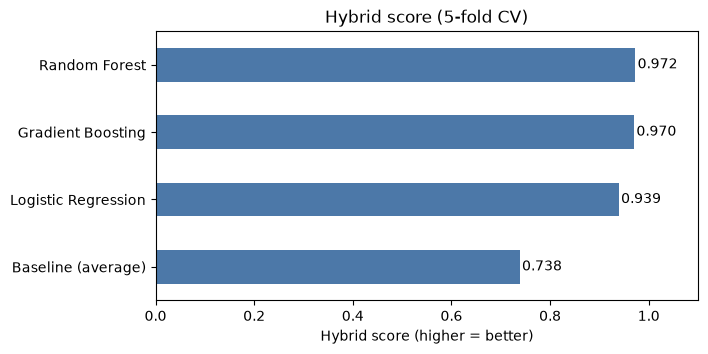

In [3]:
models = {
    "Baseline (average)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}
results = {}
for name, clf in models.items():
    scores = cross_val_score(MultiHorizonModel(make_pipeline(clf)), X, y, cv=folds, scoring=hybrid_scorer, n_jobs=-1)
    results[name] = scores.mean()

results = pd.Series(results).sort_values()
results.plot.barh(color="#4C78A8", figsize=(7, 3.5))
for i, v in enumerate(results): plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1.1); plt.title("Hybrid score (5-fold CV)"); plt.xlabel("Hybrid score (higher = better)")
plt.savefig(FIG_DIR / "02_model_comparison.png", bbox_inches="tight"); plt.show()

**Random Forest wins.** It handles the "distance below 5 km" rule and the many zero values well.

## 3. Tune the best model
Try a few settings and keep the best one.

In [4]:
grid = {"estimator__clf__min_samples_leaf": [1, 3, 5, 10], "estimator__clf__max_features": ["sqrt", 0.5]}
search = GridSearchCV(MultiHorizonModel(make_pipeline(RandomForestClassifier(n_estimators=300, random_state=42))),
                      grid, cv=folds, scoring=hybrid_scorer, n_jobs=-1).fit(X, y)
print("Best settings:", search.best_params_)
print("Hybrid score: %.3f (before tuning: %.3f)" % (search.best_score_, results["Random Forest"]))

Best settings: {'estimator__clf__max_features': 0.5, 'estimator__clf__min_samples_leaf': 5}
Hybrid score: 0.976 (before tuning: 0.972)


## 4. Save the model

In [5]:
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"model": search.best_estimator_, "features": FEATURES, "cv_hybrid": search.best_score_},
            ROOT / "models" / "fire_risk_model.joblib")
print("Saved models/fire_risk_model.joblib")

Saved models/fire_risk_model.joblib


## Summary
- **Best model:** a tuned Random Forest, one per time limit.
- It beats the baseline by a wide margin (see the chart).
- **Note:** at 72 h the model says about 98% for every fire. That's a side effect of the scoring rule, not a real forecast, so the main risk we show users is the **48 h** risk.